<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS05_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install hdbscan scikit-learn matplotlib

Jumlah data: 150
Jumlah fitur: 4
Jumlah cluster: 2
Jumlah noise: 2
Adjusted Rand Index: 0.539


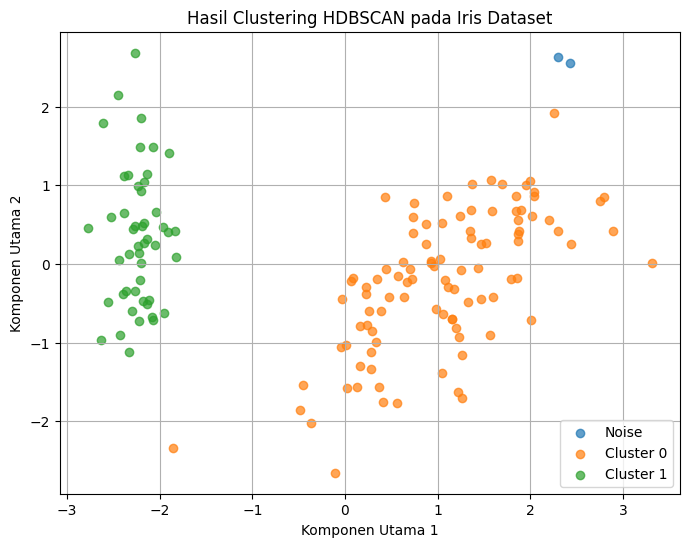

In [3]:

import hdbscan
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 1. Memuat dataset Iris
iris = load_iris()
X = iris.data
y = iris.target

print("Jumlah data:", len(X))
print("Jumlah fitur:", X.shape[1])

# 2. Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Melakukan clustering HDBSCAN
model = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

hasil_cluster = model.fit_predict(X_scaled)

# 4. Menghitung jumlah cluster dan noise
cluster_unik = set(hasil_cluster)
cluster_valid = cluster_unik - {-1}

jumlah_cluster = len(cluster_valid)
jumlah_noise = sum(hasil_cluster == -1)

print("Jumlah cluster:", jumlah_cluster)
print("Jumlah noise:", jumlah_noise)

# 5. Membandingkan dengan label asli
ari = adjusted_rand_score(y, hasil_cluster)
print("Adjusted Rand Index:", round(ari, 3))

# 6. Reduksi dimensi menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 7. Visualisasi hasil clustering
plt.figure(figsize=(8, 6))

for cluster in sorted(cluster_unik):
    mask = hasil_cluster == cluster

    if cluster == -1:
        nama = "Noise"
    else:
        nama = f"Cluster {cluster}"

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=nama,
        alpha=0.7
    )

plt.title("Hasil Clustering HDBSCAN pada Iris Dataset")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.legend()
plt.grid(True)
plt.show()


### Hasil dan Analisis Clustering HDBSCAN

**Dataset yang digunakan**

Dataset Iris dari library `sklearn.datasets`, yang terdiri dari 150 data bunga, empat fitur pengukuran, dan tiga label spesies asli, yaitu Setosa, Versicolor, dan Virginica.

**Metode**

Clustering dilakukan menggunakan algoritma HDBSCAN dengan parameter `min_cluster_size=5` dan `min_samples=5`. Sebelum proses clustering, data distandardisasi agar perbedaan skala fitur tidak mendominasi perhitungan jarak. PCA digunakan untuk mereduksi dimensi data menjadi dua komponen agar hasil clustering dapat divisualisasikan.

**Hasil**

- Jumlah cluster yang terbentuk: [isi dari hasil program].
- Jumlah data yang dianggap noise: [isi dari hasil program].
- Adjusted Rand Index (ARI): [isi dari hasil program].

**Analisis**

Hasil clustering HDBSCAN dibandingkan dengan label asli dataset Iris. Perbandingan dilakukan untuk mengetahui apakah kelompok yang dibentuk berdasarkan kepadatan data memiliki kesesuaian dengan spesies bunga yang sebenarnya.

HDBSCAN tidak menggunakan label asli ketika membentuk cluster. Oleh karena itu, hasil clustering tidak harus sama persis dengan tiga spesies pada dataset. Apabila terdapat data noise, hal tersebut menunjukkan bahwa algoritma tidak memasukkan data tersebut ke dalam cluster mana pun berdasarkan kriteria kepadatan yang digunakan.

Nilai Adjusted Rand Index digunakan sebagai ukuran tambahan untuk membandingkan hasil clustering dengan label asli. Nilai yang mendekati 1 menunjukkan kesesuaian yang tinggi, sedangkan nilai yang mendekati 0 menunjukkan kesesuaian yang setara dengan pengelompokan acak.

**Kesimpulan**

HDBSCAN dapat digunakan untuk mengelompokkan dataset Iris berdasarkan kepadatan data dan mengidentifikasi data noise. Kesesuaian hasil clustering dengan label spesies asli ditentukan berdasarkan hasil program dan nilai ARI yang diperoleh. Hasil tersebut juga dipengaruhi oleh parameter clustering yang digunakan.